# Pressure sensitivity I: Confinement

There is no pore-fluid model in these tests.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xara
from xara.units import create_units

if "thesis" in plt.style.available:
    plt.style.use("thesis")

units = create_units(system="mks")

## Common parameters

Both laws have identical elastic moduli and zero-pressure yield strength.
All hardening is disabled. `Fy` is the equivalent-stress yield parameter;
the zero-pressure **simple-shear** yield stress is `Fy / sqrt(3)`.

In [ ]:
# Elasticity
Gref = 6.0e4 * units.kPa
Kref = 3.0e5 * units.kPa
density  = 0

# Cohesion
c        = 37.0 * units.kPa
Su       = c
Fy_ref   = 2.0 * c

# Confinement
Rvol_ref = 0.1
M_prevost = 3 * np.sqrt(3/2) * Rvol_ref
phi   = np.degrees(np.arcsin(3*M_prevost / (6 + M_prevost)))

m_dp = 3*np.sqrt(3/2)*Rvol_ref

pi0_cc = 10_000*units.kPa
M_cc = np.sqrt(
    2*Fy_ref*m_dp/pi0_cc + (Fy_ref/pi0_cc)**2
)

alpha = np.sqrt(3/2) * Rvol_ref


c_cc = Fy_ref**2 / (M_cc**2 * pi0_cc)


M_pt = M_prevost/2

phase_angle = np.degrees(np.arcsin(3*M_pt/(6 + M_pt)))
dilation1 = 5*Rvol_ref/np.sqrt(1 + 3*Rvol_ref**2)

# Compaction
X0 = 10_000 * units.kPa
R  = 1 #2

p_exp = 0
p_ref = 100 * units.kPa

# The generator uses octahedral shear strain.
# Place peak strength just beyond its purely elastic strain.
peak_shear_strain = (
    1.01 * np.sqrt(2)/3 * (Fy_ref + M_prevost*p_ref) / Gref
)
smax = 0.1

del M_prevost

In [3]:
gamma_history = np.linspace(0.0, 0.005, 401)  # engineering shear strain, 0 to 0.5%
confinements = np.array([0.0, 50.0, 100.0]) * units.kPa

## Loading test

`HydrostaticShearTest.run(factory, p0, label)` ramps
all three normal stresses to $-p_0$, and commits that preload. 
It then holds the three resulting normal strains fixed while prescribing $\gamma$.

The stress-controlled preload permits reuse with different elastic moduli. For
the linear isotropic materials here it gives
$\varepsilon_{xx}=\varepsilon_{yy}=\varepsilon_{zz}=-p_0/(3K)$.

Enable any model-specific plastic stage in that factory if needed.
The stored arrays use engineering Voigt order
`[xx, yy, zz, xy, yz, zx]`; the last three strain entries are engineering shears.
Preload and shear histories are stored separately, including their endpoints.

In [4]:
from xara.examples.material import HydrostaticShearTest

In [5]:
shear_test = HydrostaticShearTest(gamma_history)

## Results


We plot:

- $\gamma=2\varepsilon_{xy}$: engineering shear strain;
- $\tau=\sigma_{xy}$: shear stress;
- $p=-(\sigma_{xx}+\sigma_{yy}+\sigma_{zz})/3$: compression-positive mean stress;
- $\varepsilon_v=\varepsilon_{xx}+\varepsilon_{yy}+\varepsilon_{zz}$: volume strain.

Here $p$ is calculated from the material stress. 

In [6]:
def drucker_shear_yield(Fy, p0, Rvol):
    return Fy / np.sqrt(3.0) + 3.0 / np.sqrt(2.0) * Rvol * p0


def plot_confinement_tests(material_models, gamma_history, confinements, reference_Rvol=None):
    shear_test = HydrostaticShearTest(gamma_history)

    confinement_results = {
        label: [shear_test.run(material, p0, label) for p0 in confinements]
        for label, material in material_models.items()
    }

    nmodels = len(confinement_results)
    fig, axes = plt.subplots(nmodels,2,
                             figsize=(6, 3.5 * nmodels),
                             sharex=True, #sharey="row", 
                             squeeze=False,
                             constrained_layout=True)

    colors = ["tab:blue", "tab:orange", "tab:green"]
    line_styles = ["-", "--", ":"]
    for col, (label, results) in enumerate(confinement_results.items()):
        print(material_models[label].asdict())
        for result, color, ls in zip(results, colors, line_styles):
            curve_label = f"$p_0$ = {result.p0 / units.kPa:.0f} kPa"
            eps = 100 * gamma_history #result.gamma

            axes[col,0].plot(eps, result.q / Fy_ref, #units.kPa,
                            color=color, ls=ls, lw=2, label=curve_label)

            axes[col,1].plot(eps, result.p / units.kPa,
                            color=color, ls=ls, lw=2)

        axes[col,0].set_title(label)
        axes[col,0].legend()
        axes[col,1].set_xlabel(r"Engineering shear strain $\gamma$ (\%)")

    axes[0, 0].set_ylabel(r"Shear stress $q/F_{y}$")
    axes[0, 1].set_ylabel(r"Pressure $p$ (kPa)")
    # for ax in axes.flat:
    #     ax.grid(alpha=0.25)
    fig.suptitle("Test 1: hydrostatic compression, then shear at fixed normal strains")


FATAL:MisesMultiyield02::Can not deal with e2p
FATAL:MisesMultiyield02::Can not deal with e2p
FATAL:MisesMultiyield02::Can not deal with e2p
FATAL:MisesMultiyield02::Can not deal with e2p
FATAL:MisesMultiyield02::Can not deal with e2p
FATAL:MisesMultiyield02::Can not deal with e2p
FATAL:MisesMultiyield02::Can not deal with e2p
FATAL:MisesMultiyield02::Can not deal with e2p
{'name': 1, 'type': 'NonlinearJ2', 'E': 168750000.0, 'nu': 0.40625, 'Fy': 74000, 'Q': [0, 0], 'b': [0, 0], 'C': [0], 'gamma': [0], 'Hiso': 0, 'gtol': 1e-16, 'MaxIter': 15, 'density': 0}
{'name': 1, 'type': 'MisesMultiyield01', 'stage': 1}
{'name': 1, 'type': 'MisesMultiyield02'}
{'name': 1, 'type': 'DruckerPrager', 'G': 60000000.0, 'K': 300000000.0, 'Fy': 74000, 'Fo': 0, 'Fs': 0, 'Hiso': 0, 'Hkin': 0, 'Hsat': 0, 'density': 0}
{'name': 1, 'type': 'CapPlasticity', 'G': 60000000.0, 'K': 300000000.0, 'density': 0, 'X': 10000000.0, 'D': 1e-07, 'W': 0.01, 'R': 1, 'lambda': 0, 'theta': 0.1, 'beta': 0, 'alpha': 60420.7, 'T':

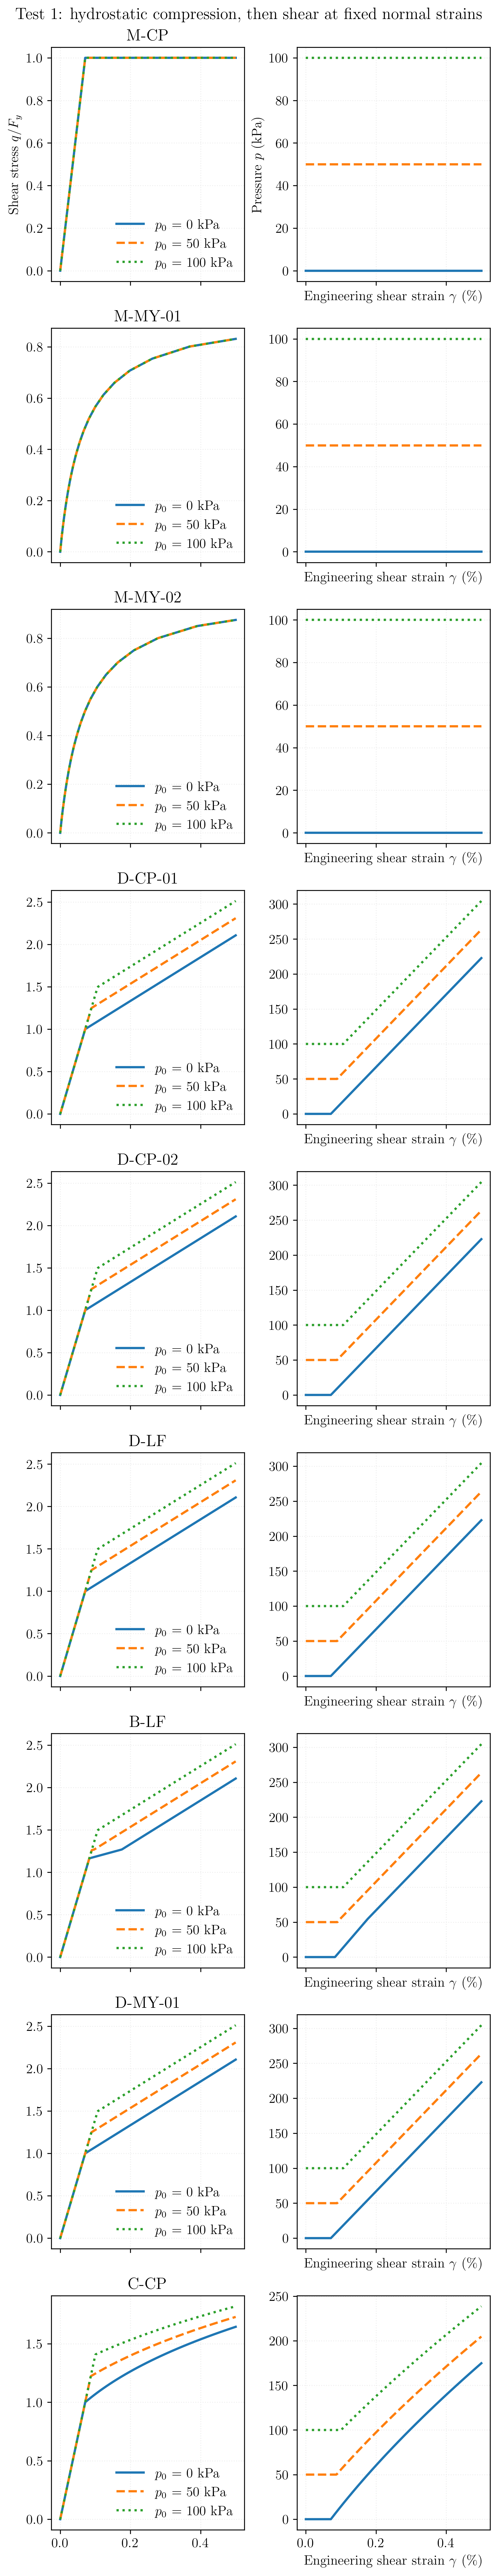

In [7]:
plot_confinement_tests({

        "M-CP": xara.MultiaxialMaterial("PlasticJ2",
                                G=Gref,
                                K=Kref,
                                Fy=Fy_ref,
        ),

        "M-MY-01": xara.MultiaxialMaterial("MisesMultiyield01",
                                3, # ndm
                                density,
                                Gref,
                                Kref,
                                2*np.sqrt(2)/3 * c,
                                smax
        ),

        "M-MY-02": xara.MultiaxialMaterial("MisesMultiyield02",
                                3, # ndm
                                density,
                                Gref,
                                Kref,
                                2*np.sqrt(2)/3 * c,
                                smax
        ),

        "D-CP-01": xara.MultiaxialMaterial(
            "DruckerPrager",
            K=Kref,
            G=Gref,
            Fy=Fy_ref,
            Rvol=Rvol_ref,
            Rbar=Rvol_ref,
            Fs=0.0, 
            Fo=0.0, 
            Hsat=0.0,
            H=0.0, 
            theta=1.0, 
            delta2=0.0,
            density=density,
            atm=units.atm,
        ),

        "D-CP-02": xara.MultiaxialMaterial(
            "CapPlasticity",
            3,
            density,
            Gref,
            Kref,
            X0,        # X: initial cap intercept
            1/X0,      # D: inverse-stress hardening scale
            0.01,                      # W: volumetric hardening scale
            R,                         # R
            0,                         # lambda
            Rvol_ref,                  # theta
            0,                         # beta
            np.sqrt(2/3)*Fy_ref,       # alpha
            Fy_ref,                    # T: constructor converts this to negative
            1e-6,                      # tolerance
        ),

        # Lee-Fenves
        "D-LF": xara.MultiaxialMaterial("LeeFenves",
                G=Gref,
                K=Kref,
                Fc=Fy_ref/(1.0-alpha),
                Ft=Fy_ref/(1.0-alpha),
                Gc=1e8, #Gc,
                Gt=1e8, #Gt,
                Lc=1,
                Lt=1,
                alpha=alpha,
                Ftype="DP",
                aC=4.0,
                alphap=np.sqrt(2/3)*alpha,
        ),
        "B-LF": xara.MultiaxialMaterial("LeeFenves",
                G=Gref,
                K=Kref,
                Fc=Fy_ref/(1.0-alpha),
                Ft=Fy_ref/(1.0-alpha),
                Gc=1e8, #Gc,
                Gt=1e8, #Gt,
                Lc=1,
                Lt=1,
                alpha=alpha,
                Ftype="BarcaOne",
                aC=4.0,
                alphap=np.sqrt(2/3)*alpha,
        ),

        # Drucker MultiYield
        "D-MY-01": xara.MultiaxialMaterial(
            "PrevostMultiYield01", #"PressureDependMultiYield", #
            3,                      # nd
            density,
            Gref,
            Kref,
            phi,                    # friction angle ≈ 36.0074 degrees
            peak_shear_strain,
            p_ref,
            p_exp,                  # pressure exponent: constant elastic moduli
            phase_angle,            # phase-transformation angle
            0.0,                    # contractionParam1
            dilation1,              # dilationParam1
            0.0,                    # dilationParam2
            0.0,                    # liquefactionParam1: disable cyclic-mobility rule
            0.0,                    # liquefactionParam2
            0.0,                    # liquefactionParam4
            1,                      # surface count: AUTOMATIC surface generation
            0.6,                    # initial void ratio
            0.9,                    # volLimit1
            0.02,                   # volLimit2
            0.7,                    # volLimit3
            units.atm,
            Fy_ref / 2,             # cohesion = 37 kPa
            0.0,                    # Hv: disable additional bulk-modulus modification
            1.0,                    # Pv: inactive when Hv=0
        ),


        # Cam-Clay
        "C-CP": xara.MultiaxialMaterial(
            "CamClayPlastic",
            K=Kref,
            G=Gref,
            M=M_cc,
            c=c_cc, # #c_cc,
            pi0=pi0_cc, #c_cc,
            e0=0.0,
            clamda=0, #1e-6,
            ckappa=0.0,
            YFtol=1e-6,
            maxIter=100,
        ),

    },

    gamma_history, confinements,
)
